In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset
df = pd.read_csv(r"C:\Users\HP\Downloads\mymoviedb.csv" , engine="python")

# Create a separate analysis dataframe
movies = df.copy()

# Clean text columns
for col in ["Title", "Genre", "Original_Language"]:
    movies[col] = movies[col].astype("string").str.strip()

# Convert date column
movies["Release_Date"] = pd.to_datetime(
    movies["Release_Date"], errors="coerce"
)

# Convert numerical columns
for col in ["Popularity", "Vote_Count", "Vote_Average"]:
    movies[col] = pd.to_numeric(
        movies[col], errors="coerce"
    )

# Remove rows missing essential analysis information
movies.dropna(
    subset=[
        "Title", "Genre", "Release_Date",
        "Popularity", "Vote_Count", "Vote_Average"
    ],
    inplace=True
)

# Remove blank genre records
movies = movies[movies["Genre"].str.strip() != ""].copy()

# Extract year and decade
movies["Release_Year"] = movies["Release_Date"].dt.year
movies["Release_Decade"] = (
    movies["Release_Year"] // 10
) * 10

# Split and explode genres
genre_df = movies.assign(
    Genre=movies["Genre"].str.split(",")
)

genre_df = genre_df.explode("Genre")

genre_df["Genre"] = genre_df["Genre"].str.strip()

genre_df = genre_df[
    genre_df["Genre"] != ""
].copy()

print("Original dataset:", df.shape)
print("Cleaned movie dataset:", movies.shape)
print("Genre-level dataset:", genre_df.shape)


Original dataset: (9837, 9)
Cleaned movie dataset: (9826, 11)
Genre-level dataset: (25792, 11)


In [3]:
#understanding genre with highest representation
genre_count = (
    genre_df.groupby("Genre")["Title"]
    .nunique()
    .sort_values(ascending=False)
)

top_10_genres = genre_count.head(10)

print(top_10_genres)


Genre
Drama        3661
Comedy       3001
Action       2629
Thriller     2425
Adventure    1814
Romance      1444
Animation    1435
Horror       1414
Family       1383
Fantasy      1276
Name: Title, dtype: int64


In [4]:
#understanding genre with highest audience rating
genre_rating = (
    genre_df.groupby("Genre")
    .agg(
        Movie_Count=("Title", "nunique"),
        Average_Rating=("Vote_Average", "mean"),
        Total_Votes=("Vote_Count", "sum")
    )
    .query("Movie_Count >= 30")
    .sort_values(
        "Average_Rating",
        ascending=False
    )
)

print(genre_rating.head(10).round(2))


             Movie_Count  Average_Rating  Total_Votes
Genre                                                
History              423            6.97     527056.0
War                  306            6.95     448918.0
Music                295            6.88     297446.0
Animation           1435            6.85    1525010.0
Western              135            6.75     186860.0
Drama               3661            6.71    5141495.0
Documentary          215            6.66      38224.0
Family              1383            6.58    2046625.0
Romance             1444            6.56    1803756.0
Crime               1220            6.55    1980261.0


In [5]:
#analyzing movies with rating above 8 and atleast 100 votes
high_rated_movies = movies[
    (movies["Vote_Average"] >= 8) &
    (movies["Vote_Count"] >= 100)
]

high_rated_movies = high_rated_movies[
    [
        "Title",
        "Release_Year",
        "Genre",
        "Vote_Average",
        "Vote_Count"
    ]
].sort_values(
    ["Vote_Average", "Vote_Count"],
    ascending=[False, False]
)

print("Total highly rated movies:", len(high_rated_movies))

print(high_rated_movies.head(15).to_string(index=False))


Total highly rated movies: 367
                                     Title  Release_Year                                 Genre  Vote_Average  Vote_Count
     The Three Deaths of Marisela Escobedo          2020                    Documentary, Crime           9.0       183.0
                 Burn the Stage: The Movie          2018                    Documentary, Music           8.9       332.0
                 Bring the Soul: The Movie          2019                    Music, Documentary           8.9       323.0
                  The Shawshank Redemption          1994                          Drama, Crime           8.7     20911.0
                             The Godfather          1972                          Drama, Crime           8.7     15614.0
               Dilwale Dulhania Le Jayenge          1995                Comedy, Drama, Romance           8.7      3474.0
              Violet Evergarden: The Movie          2020    Animation, Fantasy, Romance, Drama           8.7       195.0
 

In [6]:
#understanding genre with highest popularity
genre_popularity = (
    genre_df.groupby("Genre")
    .agg(
        Movie_Count=("Title", "nunique"),
        Average_Popularity=("Popularity", "mean"),
        Average_Rating=("Vote_Average", "mean")
    )
    .query("Movie_Count >= 30")
    .sort_values(
        "Average_Popularity",
        ascending=False
    )
)

print(genre_popularity.head(10).round(2))


                 Movie_Count  Average_Popularity  Average_Rating
Genre                                                           
Adventure               1814               53.74            6.46
Fantasy                 1276               53.08            6.53
Animation               1435               52.43            6.85
Action                  2629               50.89            6.33
Science Fiction         1248               49.51            6.26
Family                  1383               46.61            6.58
Crime                   1220               44.75            6.55
Thriller                2425               42.95            6.25
Mystery                  759               40.09            6.43
Horror                  1414               38.26            5.94


Release_Year
1902      1
1920      1
1921      2
1922      2
1925      1
1926      2
1927      2
1929      1
1930      1
1931      5
1932      5
1933      4
1935      3
1936      2
1937      2
1938      5
1939      6
1940      6
1941      6
1942      4
1943      4
1944      3
1945      2
1946      8
1947      5
1948      6
1949      6
1950      7
1951      7
1952      7
1953     10
1954     12
1955     10
1956     12
1957     12
1958     11
1959     13
1960     16
1961     17
1962     17
1963     22
1964     20
1965     21
1966     19
1967     24
1968     25
1969     24
1970     15
1971     23
1972     20
1973     40
1974     21
1975     23
1976     22
1977     37
1978     34
1979     34
1980     45
1981     48
1982     46
1983     52
1984     57
1985     80
1986     68
1987     73
1988     82
1989     80
1990     76
1991     83
1992     89
1993    118
1994    103
1995    113
1996     96
1997    117
1998    130
1999    125
2000    138
2001    164
2002    165
2003    182
2004    205
200

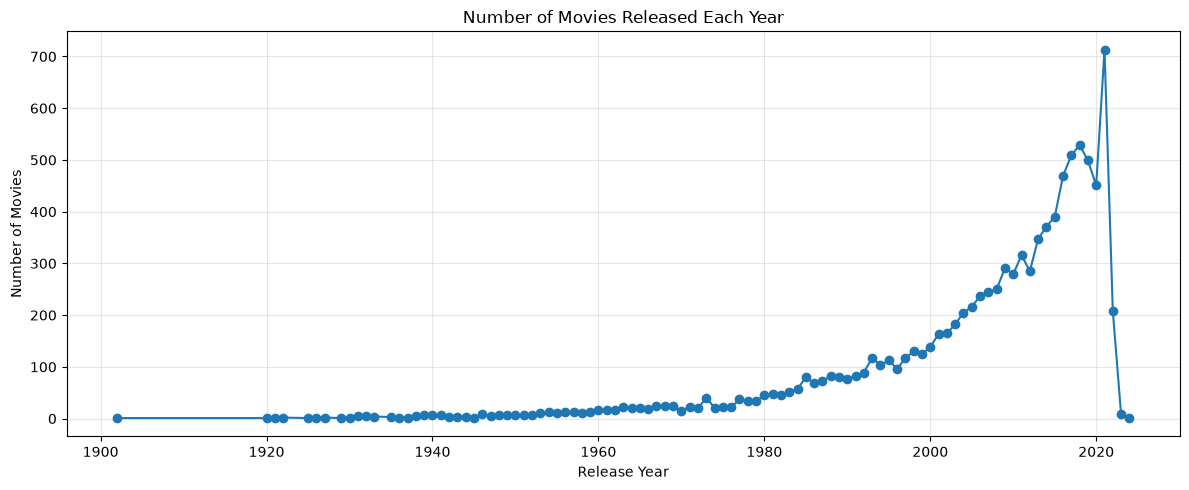

In [7]:
#understanding movies released per year
yearly_releases = (
    movies.groupby("Release_Year")["Title"]
    .nunique()
    .sort_index()
)

print(yearly_releases.to_string())

# Visualisation
plt.figure(figsize=(12, 5))

yearly_releases.plot(
    kind="line",
    marker="o"
)

plt.title("Number of Movies Released Each Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Release_Decade
2010    3968
2000    2086
2020    1379
1990    1049
1980     631
1970     269
1960     204
1950     101
1940      50
1930      33
1920      11
1900       1
Name: Title, dtype: int64


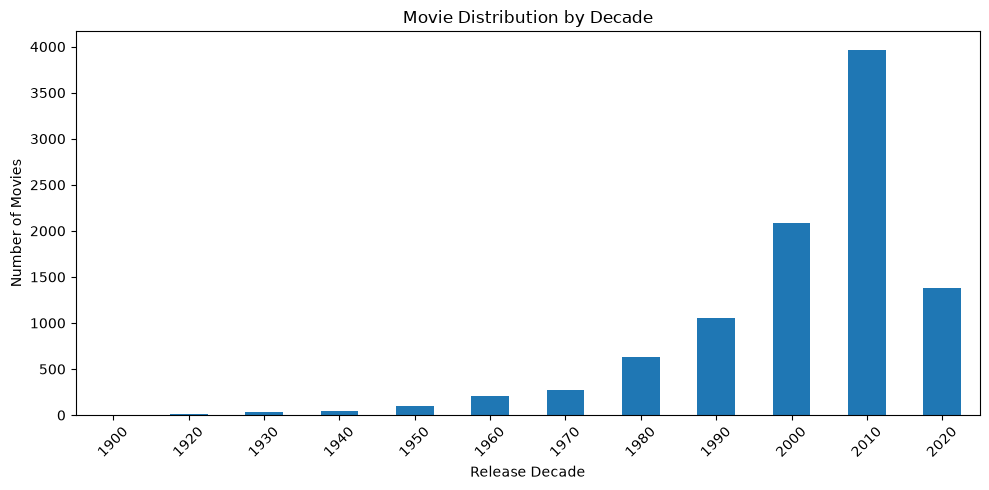

In [8]:
#understanding movies released per decade
decade_analysis = (
    movies.groupby("Release_Decade")["Title"]
    .nunique()
    .sort_values(ascending=False)
)

print(decade_analysis)

# Visualisation
plt.figure(figsize=(10, 5))

decade_analysis.sort_index().plot(
    kind="bar"
)

plt.title("Movie Distribution by Decade")
plt.xlabel("Release Decade")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


                   Movie_Count  Average_Rating  Average_Popularity
Original_Language                                                 
en                        7342            6.37               41.76
ja                         642            6.98               40.72
es                         339            6.58               37.97
fr                         290            6.31               32.92
ko                         170            6.78               33.51
zh                         129            6.74               30.02
it                         123            6.53               25.89
cn                         109            6.54               23.14
de                          82            6.73               25.94
ru                          82            6.86               39.66
pt                          37            6.48               34.46
da                          28            6.61               22.42
hi                          26            6.63               8

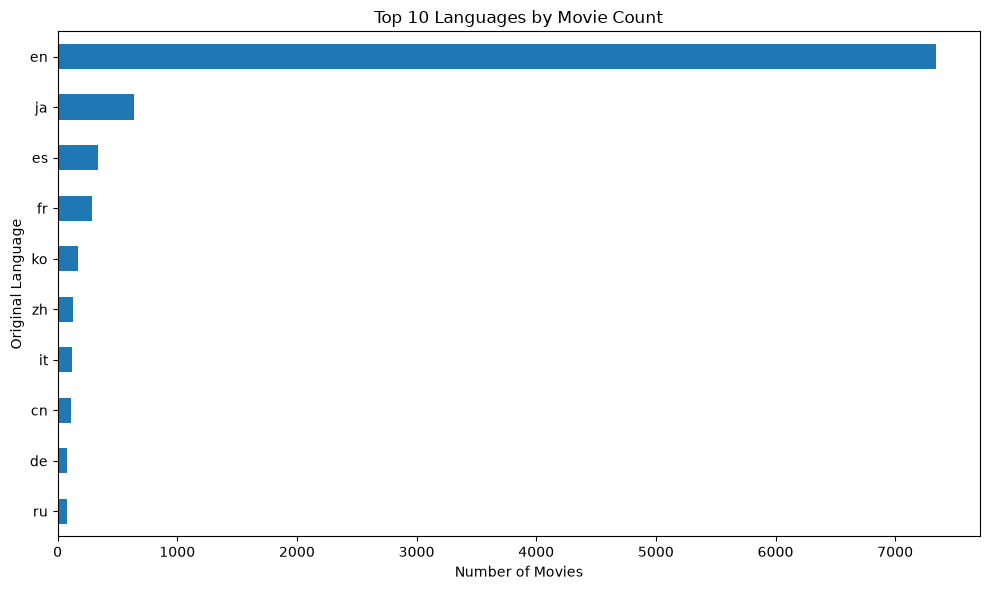

In [9]:
#understanding number of movies released in different languages
language_analysis = (
    movies.groupby("Original_Language")
    .agg(
        Movie_Count=("Title", "nunique"),
        Average_Rating=("Vote_Average", "mean"),
        Average_Popularity=("Popularity", "mean")
    )
    .sort_values(
        "Movie_Count",
        ascending=False
    )
)

print(language_analysis.head(15).round(2))

# Visualisation
plt.figure(figsize=(10, 6))

language_analysis.head(10)["Movie_Count"].sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Languages by Movie Count")
plt.xlabel("Number of Movies")
plt.ylabel("Original Language")
plt.tight_layout()
plt.show()
